### Step 3: A Function of a Random Variable

Let

$$
X\sim N(0,1), \qquad Y=X^2.
$$


In [1]:
from time import perf_counter

step3_start = perf_counter()

import sys

# Browser-specific package setup.
# Standard desktop Jupyter skips this block.
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "scipy", "matplotlib"])

print("Package setup complete.")

Package setup complete.


In [2]:
from pathlib import Path
import importlib

import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import quad
from scipy.stats import norm

%matplotlib inline

# The notebook and mp2lib.py must be in the same folder.
sys.path.insert(0, str(Path.cwd()))
importlib.invalidate_caches()

import mp2lib
importlib.reload(mp2lib)

from mp2lib import (
    inv_cdf_exponential,
    inv_cdf_rayleigh,
    sample_by_inversion,
    ks_statistic,
    q_function,
    squared_gaussian_cdf,
    squared_gaussian_pdf
)

# Reuse the team's existing MP2 setup.
if "rng_step3" not in globals():

    if "rng" in globals():
        rng_step3 = rng.spawn(1)[0]

    else:
        if "SEED" not in globals():
            SEED = 555663236  # Previously drawn example seed.

        rng = np.random.default_rng(SEED)

        (
            rng_step1,
            rng_step2,
            rng_step3,
            rng_step4,
            rng_step5,
            rng_step6,
            rng_step7,
            rng_step8
        ) = rng.spawn(8)

print("Library loaded from:", mp2lib.__file__)

if "SEED" in globals():
    print("Frozen seed:", SEED)

print("Step 3 generator ready.")

Library loaded from: /drive/notebooks/MP2/mp2lib.py
Frozen seed: 555663236
Step 3 generator ready.


#### Derive the CDF

For a standard Gaussian random variable,

$$
f_X(x)=\frac{1}{\sqrt{2\pi}}e^{-x^2/2},
\qquad F_X(x)=\Phi(x).
$$

Because $Y=X^2\ge0$,

$$
F_Y(y)=0,\qquad y<0.
$$

For $y\ge0$,

$$
\begin{aligned}
F_Y(y)
&=P[Y\le y]\\
&=P[X^2\le y]\\
&=P[-\sqrt y\le X\le\sqrt y]\\
&=F_X(\sqrt y)-F_X(-\sqrt y)\\
&=\Phi(\sqrt y)-\Phi(-\sqrt y).
\end{aligned}
$$

Using the Gaussian symmetry property,

$$
\Phi(-z)=1-\Phi(z),
$$


$$
\boxed{
F_Y(y)=
\begin{cases}
0, & y<0,\\
2\Phi(\sqrt y)-1, & y\ge0.
\end{cases}
}
$$

#### Differentiate to obtain the PDF

For $y>0$, apply the chain rule to both terms:

$$
\begin{aligned}
f_Y(y)
&=\frac{d}{dy}
\left[F_X(\sqrt y)-F_X(-\sqrt y)\right]\\
&=\frac{f_X(\sqrt y)}{2\sqrt y}
+\frac{f_X(-\sqrt y)}{2\sqrt y}\\
&=\frac{f_X(\sqrt y)+f_X(-\sqrt y)}{2\sqrt y}.
\end{aligned}
$$

Since the Gaussian PDF is symmetric,

$$
f_X(-\sqrt y)=f_X(\sqrt y).
$$

Therefore,

$$
\boxed{
f_Y(y)=\frac{e^{-y/2}}{\sqrt{2\pi y}},
\qquad y>0.
}
$$

For $y<0$, the PDF is zero. Both positive and negative values of
$X$ contribute to the density of $Y$.

#### The PDF is integrated into one

The squaring map is

$$
g(x)=x^2,
\qquad g'(x)=2x.
$$

At the origin, $g'(0)=0$, so the map is flat.

The interval

$$
[-\sqrt{\epsilon},\sqrt{\epsilon}]
$$

is compressed into the smaller interval

$$
[0,\epsilon].
$$

For small $\epsilon$,

$$
P[0\le Y\le\epsilon]
\approx 2f_X(0)\sqrt{\epsilon}
=\sqrt{\frac{2}{\pi}}\sqrt{\epsilon}.
$$

This probability tends to zero. However, its average density over
an interval of width $\epsilon$ grows proportionally to
$\epsilon^{-1/2}$.

Thus the density approaches infinity near zero, while there is
no point mass at zero.

The singularity is integrable because

$$
\int_0^1 y^{-1/2}\,dy=2.
$$

To verify normalization, substitute

$$
t=\sqrt y,
\qquad y=t^2,
\qquad dy=2t\,dt.
$$

Then

$$
\begin{aligned}
\int_0^\infty f_Y(y)\,dy
&=\int_0^\infty
\frac{e^{-y/2}}{\sqrt{2\pi y}}\,dy\\
&=\frac{2}{\sqrt{2\pi}}
\int_0^\infty e^{-t^2/2}\,dt\\
&=2P[X\ge0]\\
&=\boxed{1}.
\end{aligned}
$$

In [3]:
assert inv_cdf_exponential(0, lam=1) == 0
assert np.isclose(inv_cdf_exponential(0.5, lam=1), np.log(2))
assert inv_cdf_rayleigh(0, sigma=1) == 0
assert np.isclose(inv_cdf_rayleigh(0.5, sigma=1), np.sqrt(2 * np.log(2)))

# A deterministic input source for testing inversion.
class FixedUniforms:
    def random(self, n):
        return np.full(n, 0.5)
        
assert np.allclose(sample_by_inversion(inv_cdf_exponential, 3, FixedUniforms(), lam=1), np.full(3, np.log(2)))
assert ks_statistic([0.25, 0.75], lambda u: u) == 0.25
assert q_function(0) == 0.5
assert np.isclose(q_function(5.2), 9.96442631693348e-8, rtol=1e-12, atol=0)
assert np.allclose(squared_gaussian_cdf([-1, 0, np.inf]), [0, 0, 1])
assert np.isclose(squared_gaussian_pdf(1), norm.pdf(1))

print("All library hand checks passed.")

# Numerical normalization
integral3, integral_error3 = quad(squared_gaussian_pdf, 0, np.inf, epsabs=1e-10, epsrel=1e-10, limit=200)
regular_integral3, regular_error3 = quad(lambda t: 2 * norm.pdf(t), 0, np.inf, epsabs=1e-10, epsrel=1e-10)

print(f"\nDirect integral:             {integral3:.12f}")
print(f"Difference from 1:           {integral3 - 1:+.3e}")
print(f"Estimated quadrature error:  {integral_error3:.3e}")
print(f"Integral after y=t^2:        {regular_integral3:.12f}")

assert abs(integral3 - 1) < 1e-9
assert abs(regular_integral3 - 1) < 1e-9

All library hand checks passed.

Direct integral:             1.000000000001
Difference from 1:           +6.197e-13
Estimated quadrature error:  2.011e-11
Integral after y=t^2:        1.000000000000


#### Analytical probabilities and median

Using the derived CDF,

$$
P[Y\le1]
=2\Phi(1)-1
=\boxed{0.6826894921}.
$$

Similarly,

$$
P[Y\le0.1]
=2\Phi(\sqrt{0.1})-1
=\boxed{0.2481703660}.
$$

The median $m_Y$ satisfies

$$
F_Y(m_Y)=\frac12.
$$

Therefore,

$$
2\Phi(\sqrt{m_Y})-1=\frac12,
$$

so

$$
\Phi(\sqrt{m_Y})=\frac34.
$$

Thus,

$$
\boxed{
m_Y=[\Phi^{-1}(0.75)]^2
=0.4549364231.
}
$$

#### Analytical mean and variance

Using the lecture formula

$$
E[g(X)]
=\int_{-\infty}^{\infty}g(x)f_X(x)\,dx,
$$

the mean is

$$
E[Y]=E[X^2]
=\operatorname{Var}(X)+(E[X])^2
=1+0
=\boxed{1}.
$$

Also,

$$
E[Y^2]=E[X^4].
$$

For the standard Gaussian,

$$
f_X'(x)=-xf_X(x).
$$

Integration by parts gives

$$
\begin{aligned}
E[X^4]
&=-\int_{-\infty}^{\infty}x^3f_X'(x)\,dx\\
&=\left[-x^3f_X(x)\right]_{-\infty}^{\infty}
+3\int_{-\infty}^{\infty}x^2f_X(x)\,dx\\
&=0+3E[X^2]\\
&=3.
\end{aligned}
$$

Therefore,

$$
\boxed{
\operatorname{Var}(Y)
=E[Y^2]-(E[Y])^2
=3-1^2
=2.
}
$$

#### Simulation uncertainty

For $N$ independent observations, the SE of an estimated event
probability is

$$
\operatorname{SE}(\hat p)
=\sqrt{\frac{p(1-p)}{N}},
$$

using the known theoretical probability $p$.

For the sample mean,

$$
\operatorname{SE}(\bar Y)=\sqrt{\frac{2}{N}}.
$$

The median uses the large-sample approximation

$$
\operatorname{SE}(\hat m_Y)
\approx\frac{1}{2\sqrt N\,f_Y(m_Y)}.
$$

For the unbiased sample variance,

$$
\operatorname{SE}(s^2)
=
\sqrt{
\frac{
\mu_4-\frac{N-3}{N-1}\sigma_Y^4
}{N}
},
$$

where $\sigma_Y^2=2$ and

$$
\mu_4=E[(Y-1)^4]
=105-4(15)+6(3)-4(1)+1
=60.
$$

In [4]:
# Generate X and transform it into Y

N3 = 10**6
X3 = rng_step3.standard_normal(N3)
Y3 = X3**2

# Analytical values

p1_theory3 = float(squared_gaussian_cdf(1.0))
p01_theory3 = float(squared_gaussian_cdf(0.1))
median_theory3 = float(norm.ppf(0.75)**2)
mean_theory3 = 1.0
variance_theory3 = 2.0

# Simulation estimates

p1_mc3 = float(np.mean(Y3 <= 1.0))
p01_mc3 = float(np.mean(Y3 <= 0.1))
median_mc3 = float(np.median(Y3))
mean_mc3 = float(np.mean(Y3))
variance_mc3 = float(np.var(Y3, ddof=1))

# Standard errors

p1_se3 = np.sqrt(p1_theory3 * (1 - p1_theory3) / N3)
p01_se3 = np.sqrt(p01_theory3 * (1 - p01_theory3) / N3)
median_se3 = (1 / (2 * np.sqrt(N3) * float(squared_gaussian_pdf(median_theory3))))
mean_se3 = np.sqrt(variance_theory3 / N3)
variance_se3 = np.sqrt((60 - ((N3 - 3) / (N3 - 1)) * variance_theory3**2) / N3)

# Theory-versus-simulation table

comparisons3 = [
    ("P[Y <= 1]", p1_theory3, p1_mc3, p1_se3),
    ("P[Y <= 0.1]", p01_theory3, p01_mc3, p01_se3),
    ("Median", median_theory3, median_mc3, median_se3),
    ("Mean", mean_theory3, mean_mc3, mean_se3),
    ("Variance", variance_theory3, variance_mc3, variance_se3)
]

print(f"N = {N3:,} independent observations")
print("Sample variance uses ddof=1; median SE is asymptotic.\n")

print(
    f"{'Quantity':<16}"
    f"{'Theory':>14}"
    f"{'Simulation':>14}"
    f"{'Difference':>14}"
    f"{'SE':>13}"
    f"{'Diff / SE':>13}"
)

print("-" * 84)

for name, theory, estimate, se in comparisons3:
    difference = estimate - theory

    print(
        f"{name:<16}"
        f"{theory:>14.8f}"
        f"{estimate:>14.8f}"
        f"{difference:>+14.8f}"
        f"{se:>13.8f}"
        f"{difference / se:>+13.3f}"
    )

# Quantitative goodness-of-fit check

D3 = ks_statistic(Y3, squared_gaussian_cdf)
critical3 = 1.36 / np.sqrt(N3)

print(f"\nTwo-sided KS statistic: {D3:.8f}")
print(f"95% critical value:     {critical3:.8f}")

if D3 <= critical3:
    print("The test does not reject the derived CDF at the 5% level.")
else:
    print("The test rejects the derived CDF at the 5% level.")
    print("Retain the frozen seed and report this result.")

# Verify the assignment's analytical reference values

assert np.allclose(
    [
        p1_theory3,
        p01_theory3,
        median_theory3,
        mean_theory3,
        variance_theory3
    ],
    [
        0.6826894921370859,
        0.2481703659541507,
        0.4549364231195727,
        1,
        2
    ],
    rtol=0,
    atol=1e-12
)

N = 1,000,000 independent observations
Sample variance uses ddof=1; median SE is asymptotic.

Quantity                Theory    Simulation    Difference           SE    Diff / SE
------------------------------------------------------------------------------------
P[Y <= 1]           0.68268949    0.68332900   +0.00063951   0.00046543       +1.374
P[Y <= 0.1]         0.24817037    0.24850600   +0.00033563   0.00043195       +0.777
Median              0.45493642    0.45382049   -0.00111593   0.00106126       -1.052
Mean                1.00000000    0.99824840   -0.00175160   0.00141421       -1.239
Variance            2.00000000    1.99933239   -0.00066761   0.00748332       -0.089

Two-sided KS statistic: 0.00110672
95% critical value:     0.00136000
The test does not reject the derived CDF at the 5% level.


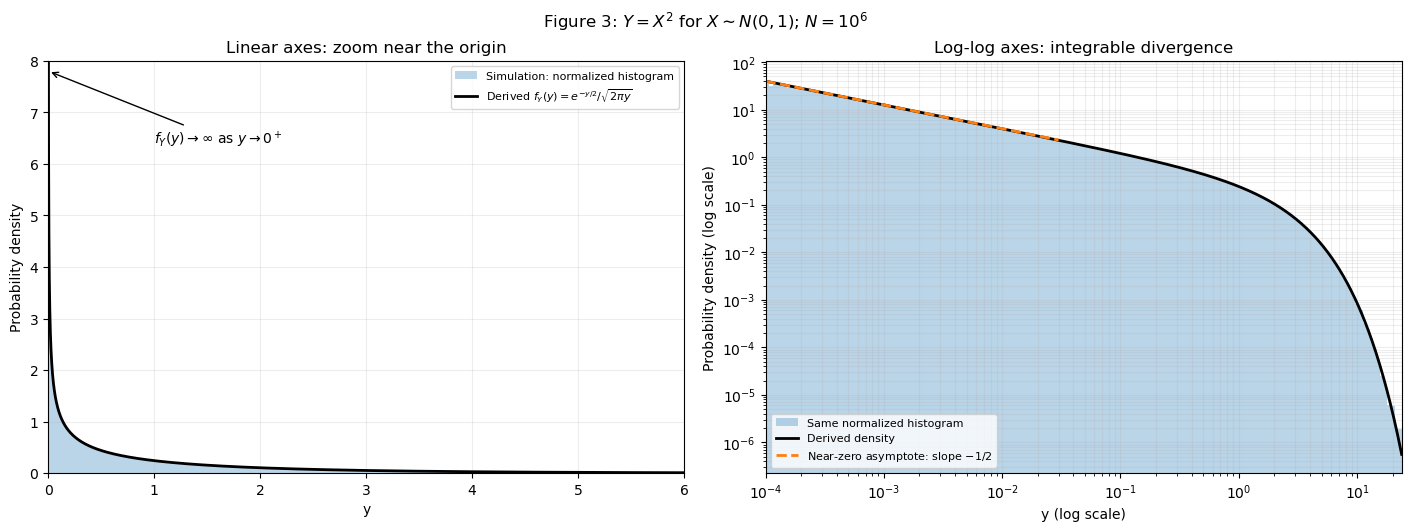

Histogram includes 1,000,000 of 1,000,000 samples.
Histogram area: 1.000000000000
Limiting log-log slope near zero: -0.5
Step 3 elapsed time: 15.534 seconds


In [5]:
# Construct and normalize the histogram

first_edge3 = 1e-4
last_edge3 = max(12.0, float(Y3.max()) * 1.001)
edges3 = np.r_[0.0, np.geomspace(first_edge3, last_edge3, 180)]
counts3, _ = np.histogram(Y3, bins=edges3)
density3 = counts3 / (N3 * np.diff(edges3))
histogram_area3 = np.sum(density3 * np.diff(edges3))

assert counts3.sum() == N3
assert np.isclose(histogram_area3, 1.0)

# Evaluate the derived density at positive y

plot_y3 = np.geomspace(first_edge3, last_edge3, 1800)
plot_pdf3 = squared_gaussian_pdf(plot_y3)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), layout="constrained")

# Left panel: linear axes

axes[0].stairs(density3, edges3, fill=True, alpha=0.3, color="tab:blue", 
               label="Simulation: normalized histogram")
axes[0].plot(plot_y3, plot_pdf3, color="black", linewidth=2, 
             label=r"Derived $f_Y(y)=e^{-y/2}/\sqrt{2\pi y}$")
axes[0].set(
    xlim=(0, 6), 
    ylim=(0, 8), xlabel="y", 
    ylabel="Probability density", 
    title="Linear axes: zoom near the origin"
)
axes[0].annotate(r"$f_Y(y)\to\infty$ as $y\to0^+$", xy=(0.003, 7.8), xytext=(1.0, 6.4), arrowprops={"arrowstyle": "->"})

# Right panel: log-log axes
# Omit the zero-edge bin from the logarithmic display only.

axes[1].stairs(density3[1:], edges3[1:], fill=True, alpha=0.3, color="tab:blue", 
               label="Same normalized histogram")
axes[1].plot(plot_y3, plot_pdf3, color="black", linewidth=2, 
             label="Derived density")

small_y3 = np.geomspace(first_edge3, 0.03, 200)

axes[1].plot(small_y3, 1 / np.sqrt(2 * np.pi * small_y3), "--", color="tab:orange", linewidth=2, label=r"Near-zero asymptote: slope $-1/2$")
axes[1].set(
    xscale="log",
    yscale="log",
    xlim=(first_edge3, last_edge3),
    xlabel="y (log scale)",
    ylabel="Probability density (log scale)",
    title="Log-log axes: integrable divergence"
)

axes[0].legend(loc="upper right", fontsize=8)
axes[1].legend(loc="lower left", fontsize=8)

for ax in axes:
    ax.grid(which="both", alpha=0.22)

fig.suptitle(r"Figure 3: $Y=X^2$ for $X\sim N(0,1)$; $N=10^6$")

plt.show()

print(f"Histogram includes {counts3.sum():,} "f"of {N3:,} samples.")
print(f"Histogram area: {histogram_area3:.12f}")
print("Limiting log-log slope near zero: -0.5")
print(f"Step 3 elapsed time: "f"{perf_counter() - step3_start:.3f} seconds")

The histogram uses a first bin from $0$ to $10^{-4}$,
followed by log-spaced bins extending beyond the largest
observed value.

Because the bins have different widths, each density height is

$$
h_j=
\frac{\text{number of observations in bin }j}
{N\,(\text{width of bin }j)}.
$$

Therefore,

$$
\sum_j h_j(\text{width of bin }j)=1.
$$

All observations are included in this normalization.

The linear panel displays a zoom with $0\le y\le6$ and density
up to 8. The log-log panel shows the positive part of the same
histogram. The zero-edge bin cannot be displayed on a logarithmic
x-axis.

A histogram height is an average density over a bin. Its finite
height is consistent with a PDF whose endpoint limit is infinite.

For small positive $y$,

$$
f_Y(y)\sim\frac{1}{\sqrt{2\pi}}y^{-1/2}.
$$

Equivalently,

$$
\ln f_Y(y)
=
-\frac12\ln(2\pi)
-\frac12\ln y
-\frac y2.
$$

Hence,

$$
\frac{d\ln f_Y}{d\ln y}
=-\frac12-\frac y2
\longrightarrow-\frac12
\quad\text{as }y\to0^+.
$$

The straight near-zero section on the log-log plot therefore has
limiting slope

$$
\boxed{-\frac12}.
$$

At larger $y$, the exponential factor bends the curve downward.


Squaring both positive and negative Gaussian observations produces
a nonnegative random variable with much of its probability near
zero. The squaring map is flat at the origin, causing the density
to grow without bound as $y\to0^+$.

The log-log panel reveals the near-zero power-law behavior:
$f_Y(y)$ is approximately proportional to $y^{-1/2}$, giving a
slope of $-1/2$. At larger values of $y$, the exponential factor
causes a faster decline.

Despite its unbounded density, the distribution has total
probability one. The numerical integral and normalized-histogram
area verify this.

The comparison table reports the actual simulation differences
and standard errors for the two probabilities, median, mean, and
variance. The KS statistic is compared with the 95% critical value
of $0.00136$ at $N=10^6$, providing a quantitative CDF check.

The theoretical median is approximately $0.4549$, below the mean
of $1$. The concentration near zero and the extended right tail
make this distribution right-skewed.